# Исследовательский анализ данных (EDA)
Heart Failure Prediction Dataset — прогнозирование риска сердечно-сосудистых заболеваний.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../data/heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [3]:
df.describe().round(2)

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.00,918.00,918.00,918.00,918.00,918.00,918.00
mean,53.51,132.40,198.80,0.23,136.81,0.89,0.55
std,9.43,18.51,109.38,0.42,25.46,1.07,0.50
min,28.00,0.00,0.00,0.00,60.00,-2.60,0.00
25%,47.00,120.00,173.25,0.00,120.00,0.00,0.00
50%,54.00,130.00,223.00,0.00,138.00,0.60,1.00
75%,60.00,140.00,267.00,0.00,156.00,1.50,1.00
max,77.00,200.00,603.00,1.00,202.00,6.20,1.00


## Пропуски и дубликаты
Формально пропусков нет, но нулевые значения холестерина и давления физиологически невозможны — это скрытые пропуски.

In [4]:
print("NaN:", df.isna().sum().sum(), "| дубликаты:", df.duplicated().sum())
print("Cholesterol = 0:", (df.Cholesterol == 0).sum(), "| RestingBP = 0:", (df.RestingBP == 0).sum())
print("Доля больных среди Cholesterol = 0:", round(df[df.Cholesterol == 0].HeartDisease.mean(), 3))

NaN: 0 | дубликаты: 0
Cholesterol = 0: 172 | RestingBP = 0: 1
Доля больных среди Cholesterol = 0: 0.884


## Баланс классов и категориальные признаки

In [5]:
print(df.HeartDisease.value_counts())
for col in ["Sex", "ChestPainType", "ST_Slope", "ExerciseAngina"]:
    print((df.groupby(col).HeartDisease.mean() * 100).round(1), "\n")

HeartDisease
1    508
0    410
Name: count, dtype: int64
Sex
F    25.9
M    63.2
Name: HeartDisease, dtype: float64 

ChestPainType
ASY    79.0
ATA    13.9
NAP    35.5
TA     43.5
Name: HeartDisease, dtype: float64 

ST_Slope
Down    77.8
Flat    82.8
Up      19.7
Name: HeartDisease, dtype: float64 

ExerciseAngina
N    35.1
Y    85.2
Name: HeartDisease, dtype: float64 



## Распределения числовых признаков

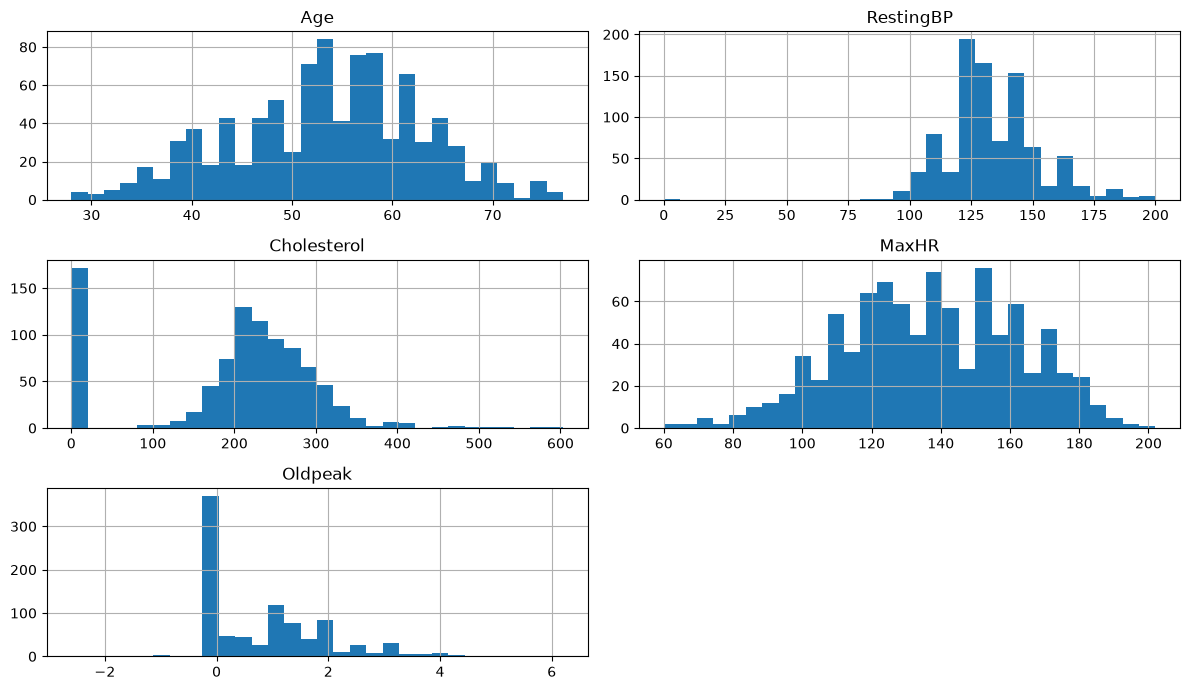

In [6]:
num = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
df[num].hist(bins=30, figsize=(12, 7))
plt.tight_layout(); plt.show()

## Выбросы (правило IQR, после замены нулей на пропуски)

Age 0
RestingBP 27
Cholesterol 23
MaxHR 2
Oldpeak 16


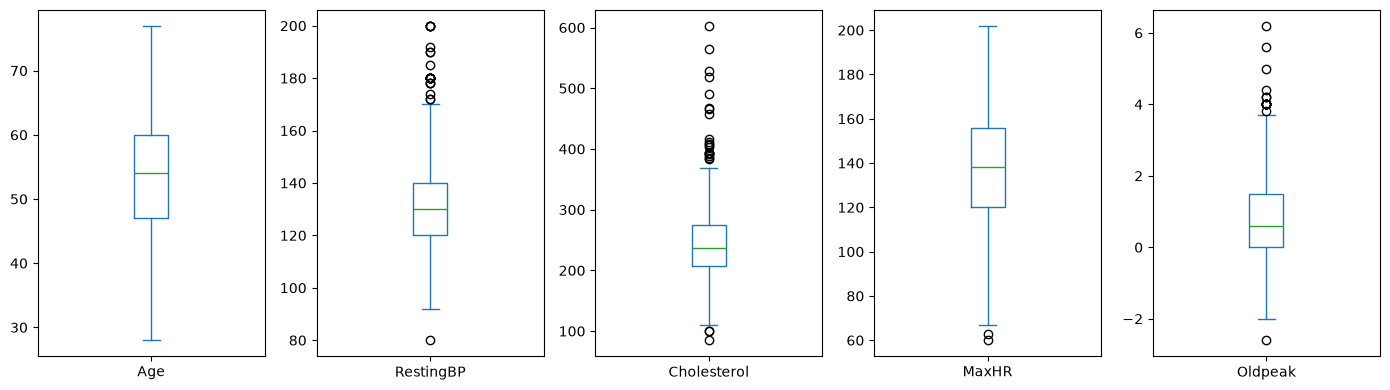

In [7]:
clean = df[df.RestingBP > 0].copy()
clean.loc[clean.Cholesterol == 0, "Cholesterol"] = np.nan
for col in num:
    q1, q3 = clean[col].quantile([.25, .75]); iqr = q3 - q1
    print(col, int(((clean[col] < q1 - 1.5 * iqr) | (clean[col] > q3 + 1.5 * iqr)).sum()))
clean[num].plot(kind="box", subplots=True, layout=(1, 5), figsize=(14, 4)); plt.tight_layout(); plt.show()

## Корреляции

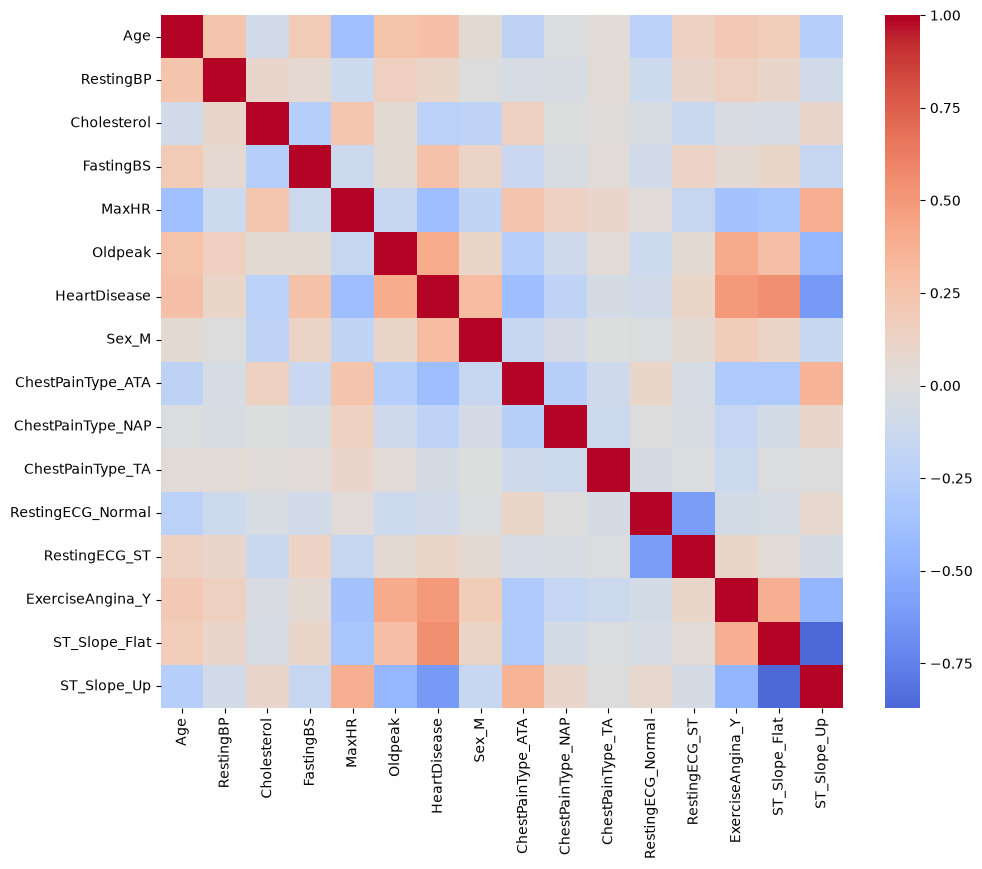

ST_Slope_Up         -0.62
ChestPainType_ATA   -0.40
MaxHR               -0.40
Cholesterol         -0.23
ChestPainType_NAP   -0.21
RestingECG_Normal   -0.09
ChestPainType_TA    -0.05
RestingECG_ST        0.10
RestingBP            0.11
FastingBS            0.27
Age                  0.28
Sex_M                0.31
Oldpeak              0.40
ExerciseAngina_Y     0.49
ST_Slope_Flat        0.55
Name: HeartDisease, dtype: float64

In [8]:
enc = pd.get_dummies(df, drop_first=True, dtype=int)
plt.figure(figsize=(11, 9))
sns.heatmap(enc.corr(), cmap="coolwarm", center=0)
plt.show()
enc.corr()["HeartDisease"].drop("HeartDisease").sort_values().round(2)